# Regression algorithms: KNN, Decision Trees and Random Forests

In this notebook we are going to review three regression algorithms: K-Nearest Neighbours, Decision Trees and Random Forest.

## 0. Dataset and setup

The dataset represents house prices. The variables are deliberately familiar so that attention stays on the algorithms.

| Variable | Type | Interpretation |
|---|---|---|
| size_m2 | numerical | house size |
| distance_to_center_km | numerical | distance to the city centre |
| age_years | numerical | age of the property |
| bedrooms | numerical/discrete | number of bedrooms |
| renovated | nominal categorical | whether it was renovated |
| energy_rating | ordinal categorical | energy efficiency from E to A |
| neighborhood | nominal categorical | broad area type |
| price_k_eur | target | price in thousands of euros |

We keep a **train / validation / test** split. Hyperparameters are explored with the validation set. The test set is left untouched until the final comparison.

In [1]:
# The implementation details in this cell are not part of the lesson.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

# ---------- Data ----------
n = 320
size = rng.uniform(40, 180, n)
distance = rng.uniform(0.5, 15, n)
age = rng.integers(0, 61, n)
bedrooms = np.clip(np.rint(size / 35 + rng.normal(0, 0.55, n)), 1, 6).astype(int)
renovated = np.where(rng.random(n) < (0.12 + 0.006 * age), "yes", "no")
neighborhood = rng.choice(["urban", "suburban", "residential"], n, p=[0.30, 0.42, 0.28])

energy_score = 4.4 - age / 20 + (renovated == "yes") * 1.2 + rng.normal(0, 0.8, n)
energy_num = np.clip(np.rint(energy_score), 0, 4).astype(int)
energy_rating = np.array(["E", "D", "C", "B", "A"])[energy_num]

energy_effect = pd.Series(energy_rating).map({"E": -25, "D": -12, "C": 0, "B": 15, "A": 30}).to_numpy()
neighborhood_effect = pd.Series(neighborhood).map({"urban": 22, "suburban": 8, "residential": 0}).to_numpy()

price = (
    55
    + 2.15 * size
    - 7.2 * distance
    - 0.75 * age
    + 9.0 * bedrooms
    + (renovated == "yes") * 28
    + energy_effect
    + neighborhood_effect
    + 14 * np.sin(size / 25)
    + rng.normal(0, 18, n)
)

houses = pd.DataFrame({
    "size_m2": size.round(1),
    "distance_to_center_km": distance.round(2),
    "age_years": age,
    "bedrooms": bedrooms,
    "renovated": renovated,
    "energy_rating": energy_rating,
    "neighborhood": neighborhood,
    "price_k_eur": price.round(1),
})

X = houses.drop(columns="price_k_eur")
y = houses["price_k_eur"]
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.40, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=RANDOM_STATE)

num_cols = ["size_m2", "distance_to_center_km", "age_years", "bedrooms"]
nominal_cols = ["renovated", "neighborhood"]
ordinal_cols = ["energy_rating"]

knn_2d_cols = ["size_m2", "distance_to_center_km"]
X_knn_train = X_train[knn_2d_cols]

# ---------- Preprocessing ----------
tree_preprocess = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
    ("ordinal", OrdinalEncoder(categories=[["E", "D", "C", "B", "A"]]), ordinal_cols),
], verbose_feature_names_out=False)

knn_full_preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
    ("ordinal", OrdinalEncoder(categories=[["E", "D", "C", "B", "A"]]), ordinal_cols),
], verbose_feature_names_out=False)

# ---------- Small helpers ----------

# Computes the three regression metrics used throughout the notebook.
def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

# Shows which observations become the nearest neighbors of the same query as k increases.
def plot_knn_neighborhoods(k_values=(1, 3, 5, 11), query=(110.0, 4.0)):
    scaler = StandardScaler().fit(X_knn_train)
    Xs = scaler.transform(X_knn_train)
    qs = scaler.transform(pd.DataFrame([query], columns=knn_2d_cols))
    fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True, constrained_layout=True)
    sc = None
    for ax, k in zip(axes.ravel(), k_values):
        knn = KNeighborsRegressor(n_neighbors=k).fit(Xs, y_train)
        _, idx = knn.kneighbors(qs)
        pred = knn.predict(qs)[0]
        neigh = X_knn_train.iloc[idx[0]]
        sc = ax.scatter(X_knn_train.iloc[:, 0], X_knn_train.iloc[:, 1], c=y_train, alpha=.45)
        ax.scatter(neigh.iloc[:, 0], neigh.iloc[:, 1], s=130, facecolors="none", edgecolors="black", linewidths=1.8)
        ax.scatter(query[0], query[1], marker="*", s=250, color="black")
        ax.set_title(f"k={k}  →  prediction ≈ {pred:.0f} k€")
        ax.set_xlabel("size_m2")
        ax.set_ylabel("distance_to_center_km")
    fig.colorbar(sc, ax=axes.ravel().tolist(), label="price_k_eur", shrink=.85)
    fig.suptitle("The same query uses a wider neighborhood as k increases", y=1.01)
    plt.show()

# Compares the neighbors selected in raw units with those selected after standardization.
def plot_knn_scaling(query=(110.0, 4.0), k=5):
    q = pd.DataFrame([query], columns=knn_2d_cols)
    raw_model = KNeighborsRegressor(n_neighbors=k).fit(X_knn_train, y_train)
    _, raw_idx = raw_model.kneighbors(q)

    scaler = StandardScaler().fit(X_knn_train)
    Xs = scaler.transform(X_knn_train)
    qs = scaler.transform(q)
    scaled_model = KNeighborsRegressor(n_neighbors=k).fit(Xs, y_train)
    _, scaled_idx = scaled_model.kneighbors(qs)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    for ax, idx, title in [
        (axes[0], raw_idx[0], "Neighbors chosen with raw units"),
        (axes[1], scaled_idx[0], "Neighbors chosen after StandardScaler"),
    ]:
        ax.scatter(X_knn_train.iloc[:, 0], X_knn_train.iloc[:, 1], alpha=.28)
        neigh = X_knn_train.iloc[idx]
        ax.scatter(neigh.iloc[:, 0], neigh.iloc[:, 1], s=150, facecolors="none", edgecolors="black", linewidths=2)
        ax.scatter(query[0], query[1], marker="*", s=260, color="black")
        ax.set_title(title)
        ax.set_xlabel("size_m2")
        ax.set_ylabel("distance_to_center_km")
    fig.suptitle("Scaling can change which observations are considered 'near'", y=1.02)
    plt.tight_layout()
    plt.show()

# Enumerates candidate numerical splits and computes how much each one reduces squared error.
def numeric_split_candidates(Xraw, yraw, features=None, max_candidates=60):
    if features is None:
        features = num_cols
    parent_mse = np.mean((yraw - yraw.mean())**2)
    rows = []
    for f in features:
        vals = np.sort(Xraw[f].unique())
        thresholds = (vals[:-1] + vals[1:]) / 2
        if len(thresholds) > max_candidates:
            idx = np.linspace(0, len(thresholds)-1, max_candidates).astype(int)
            thresholds = thresholds[idx]
        for t in thresholds:
            left = yraw[Xraw[f] <= t]
            right = yraw[Xraw[f] > t]
            if len(left) < 8 or len(right) < 8:
                continue
            mse_l = np.mean((left-left.mean())**2)
            mse_r = np.mean((right-right.mean())**2)
            weighted = (len(left)*mse_l + len(right)*mse_r) / len(yraw)
            rows.append({"feature": f, "threshold": t, "weighted_child_MSE": weighted, "MSE_reduction": parent_mse-weighted,
                         "n_left": len(left), "n_right": len(right)})
    return pd.DataFrame(rows).sort_values("MSE_reduction", ascending=False)

# Visualizes the best candidate split and the error criterion used to select it.
def show_split_search():
    cand = numeric_split_candidates(X_train, y_train)
    best = cand.iloc[0]
    f = best.feature
    d = cand[cand.feature == f].sort_values("threshold")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(d.threshold, d.weighted_child_MSE)
    axes[0].axvline(best.threshold, linestyle="--")
    axes[0].set_title(f"Candidate thresholds for {f}")
    axes[0].set_xlabel("threshold")
    axes[0].set_ylabel("weighted child MSE")

    left = X_train[f] <= best.threshold
    axes[1].scatter(X_train.loc[left, f], y_train[left], alpha=.55, label="left child")
    axes[1].scatter(X_train.loc[~left, f], y_train[~left], alpha=.55, label="right child")
    axes[1].axvline(best.threshold, linestyle="--")
    axes[1].set_title(f"Best shown split: {f} ≤ {best.threshold:.1f}")
    axes[1].set_xlabel(f)
    axes[1].set_ylabel("price_k_eur")
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    display(cand.head(6).reset_index(drop=True))

# Builds a regression-tree pipeline with the requested complexity controls.
def make_tree(max_depth=None, min_samples_leaf=1, min_samples_split=2):
    return Pipeline([
        ("preprocess", clone(tree_preprocess)),
        ("model", DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=max_depth,
                                        min_samples_leaf=min_samples_leaf, min_samples_split=min_samples_split)),
    ])

# Fits and draws a deliberately shallow tree so its recursive rules can be read directly.
def show_shallow_tree():
    m = make_tree(max_depth=2, min_samples_leaf=12)
    m.fit(X_train, y_train)
    names = m.named_steps["preprocess"].get_feature_names_out()
    plt.figure(figsize=(16, 6))
    plot_tree(m.named_steps["model"], feature_names=names, filled=True, rounded=True, precision=1)
    plt.title("A shallow regression tree: each internal node is a rule; each leaf stores a prediction")
    plt.show()

# Evaluates the main tree-complexity hyperparameters one at a time on train and validation data.
def tree_sweep():
    configs = {
        "max_depth": [2, 3, 4, 5, 7, 10, None],
        "min_samples_leaf": [1, 2, 5, 10, 20, 35],
        "min_samples_split": [2, 5, 10, 20, 40],
    }
    rows = []
    for param, values in configs.items():
        for v in values:
            kw = {"max_depth": 7, "min_samples_leaf": 2, "min_samples_split": 2}
            kw[param] = v
            m = make_tree(**kw)
            m.fit(X_train, y_train)
            for split, XX, yy in [("train", X_train, y_train), ("validation", X_val, y_val)]:
                rows.append({"parameter": param, "value": "None" if v is None else str(v), "order": len(rows),
                             "split": split, "RMSE": root_mean_squared_error(yy, m.predict(XX))})
    return pd.DataFrame(rows)

# Plots how each tree-complexity control changes train and validation error.
def plot_tree_sweep(df):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, param in zip(axes, ["max_depth", "min_samples_leaf", "min_samples_split"]):
        d = df[df.parameter == param]
        vals = list(dict.fromkeys(d.value.tolist()))
        x = np.arange(len(vals))
        for split in ["train", "validation"]:
            dd = d[d.split == split]
            ax.plot(x, dd.RMSE, marker="o", label=split)
        ax.set_xticks(x, vals, rotation=25)
        ax.set_title(param)
        ax.set_ylabel("RMSE")
        ax.legend()
    plt.tight_layout()
    plt.show()

# Creates a controlled path in feature space so individual forest trees can be compared along house size.
def controlled_path(n_points=140):
    sizes = np.linspace(45, 175, n_points)
    return pd.DataFrame({
        "size_m2": sizes,
        "distance_to_center_km": 5.0,
        "age_years": 15,
        "bedrooms": 3,
        "renovated": "no",
        "energy_rating": "C",
        "neighborhood": "suburban",
    })

# Builds a random-forest pipeline with the requested ensemble and tree controls.
def make_forest(n_estimators=300, max_features=1.0, max_depth=None, min_samples_leaf=1, max_samples=None):
    return Pipeline([
        ("preprocess", clone(tree_preprocess)),
        ("model", RandomForestRegressor(n_estimators=n_estimators, max_features=max_features,
                                        max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                        max_samples=max_samples, bootstrap=True,
                                        random_state=RANDOM_STATE, n_jobs=-1)),
    ])

# Shows several individual tree predictions and the smoother prediction obtained by averaging them.
def show_forest_predictions(n_estimators=40, max_features=.7):
    m = make_forest(n_estimators=n_estimators, max_features=max_features, min_samples_leaf=2)
    m.fit(X_train, y_train)
    path = controlled_path()
    Xp = m.named_steps["preprocess"].transform(path)
    forest = m.named_steps["model"]
    indiv = np.asarray([est.predict(Xp) for est in forest.estimators_])

    fig, ax = plt.subplots(figsize=(9, 5))
    for pred in indiv[:15]:
        ax.plot(path.size_m2, pred, alpha=.16)
    ax.plot(path.size_m2, indiv.mean(axis=0), linewidth=3, color="black", label="forest average")
    ax.set_title("Random forest: many different tree predictions are averaged")
    ax.set_xlabel("size_m2 (other features held fixed)")
    ax.set_ylabel("predicted price_k_eur")
    ax.legend()
    plt.tight_layout()
    plt.show()

# Compares how sensitive a single tree and a random forest are to changes in the sampled training data.
def compare_resampling_stability(repeats=24):
    tree_scores, forest_scores = [], []
    for seed in range(repeats):
        rr = np.random.default_rng(seed)
        idx = rr.choice(len(X_train), len(X_train), replace=True)
        Xb, yb = X_train.iloc[idx], y_train.iloc[idx]
        tree = make_tree(max_depth=None, min_samples_leaf=1).fit(Xb, yb)
        forest = make_forest(n_estimators=120, max_features=.7, min_samples_leaf=2).fit(Xb, yb)
        tree_scores.append(root_mean_squared_error(y_val, tree.predict(X_val)))
        forest_scores.append(root_mean_squared_error(y_val, forest.predict(X_val)))

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.boxplot([tree_scores, forest_scores], tick_labels=["single tree", "random forest"])
    ax.set_ylabel("Validation RMSE")
    ax.set_title("Sensitivity to the training sample")
    plt.tight_layout()
    plt.show()

    return pd.DataFrame({
        "model": ["single tree", "random forest"],
        "mean_validation_RMSE": [np.mean(tree_scores), np.mean(forest_scores)],
        "std_across_resamples": [np.std(tree_scores), np.std(forest_scores)],
    })

# Measures how feature subsampling changes individual-tree quality, tree correlation, and forest error.
def forest_diversity_demo():
    pre = clone(tree_preprocess).fit(X_train)
    Xt, Xv = pre.transform(X_train), pre.transform(X_val)
    rows = []

    for label, max_features in [("all features", 1.0), ("sqrt(features)", "sqrt")]:
        rf = RandomForestRegressor(
            n_estimators=100,
            max_features=max_features,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ).fit(Xt, y_train)
        preds = np.vstack([e.predict(Xv) for e in rf.estimators_])
        corr = np.corrcoef(preds)
        tri = corr[np.triu_indices_from(corr, k=1)]
        indiv_rmse = [root_mean_squared_error(y_val, p) for p in preds]
        rows.append({
            "max_features setting": label,
            "mean_tree_RMSE": np.mean(indiv_rmse),
            "avg_pairwise_tree_correlation": np.nanmean(tri),
            "forest_RMSE": root_mean_squared_error(y_val, rf.predict(Xv)),
        })

    return pd.DataFrame(rows)

# Builds the full-feature KNN pipeline used in the final like-for-like comparison.
def make_full_knn(k=11, weights="distance", p=2):
    return Pipeline([
        ("preprocess", clone(knn_full_preprocess)),
        ("model", KNeighborsRegressor(n_neighbors=k, weights=weights, p=p)),
    ])

# Fits one model once and returns its metrics on train, validation, and test partitions.
def evaluate_on_splits(name, model):
    model.fit(X_train, y_train)
    rows = []
    for split, XX, yy in [("train", X_train, y_train), ("validation", X_val, y_val), ("test", X_test, y_test)]:
        rows.append({"model": name, "split": split, **metrics(yy, model.predict(XX))})
    return rows


In [2]:
display(houses.head(6))
pd.DataFrame({"split": ["train", "validation", "test"], "rows": [len(X_train), len(X_val), len(X_test)]})

,size_m2,distance_to_center_km,age_years,bedrooms,renovated,energy_rating,neighborhood,price_k_eur
0,148.4,13.79,45,5,no,C,suburban,323.7
1,101.4,7.47,45,4,no,A,residential,226.7
2,160.2,5.26,23,5,no,A,suburban,404.2
3,137.6,8.26,48,5,no,C,suburban,280.7
4,53.2,12.80,23,2,no,C,urban,123.7
5,176.6,9.96,2,5,no,A,residential,455.2


,split,rows
0,train,192
1,validation,64
2,test,64


# 1. KNN regression — prediction by local similarity

K-nearest neighbors is easiest to understand geometrically.

For a new observation \(x\):

1. represent every training observation as a point in feature space;
2. measure the distance from \(x\) to the training points;
3. select the \(k\) closest points;
4. average their target values.

With two numerical features, Euclidean distance is

$$
d(x,z)=\sqrt{(x_1-z_1)^2+(x_2-z_2)^2}.
$$

We will use only size_m2 and distance_to_center_km at first. The library computes the distances; we focus on **what neighborhood is created**.

## 1.1 What does changing `k` actually do?

The star is a new house. Circled points are the neighbors used for its prediction.

- **small `k`** → very local prediction, low smoothing, high sensitivity to individual observations;
- **large `k`** → wider neighborhood, smoother prediction, more bias toward the local average.

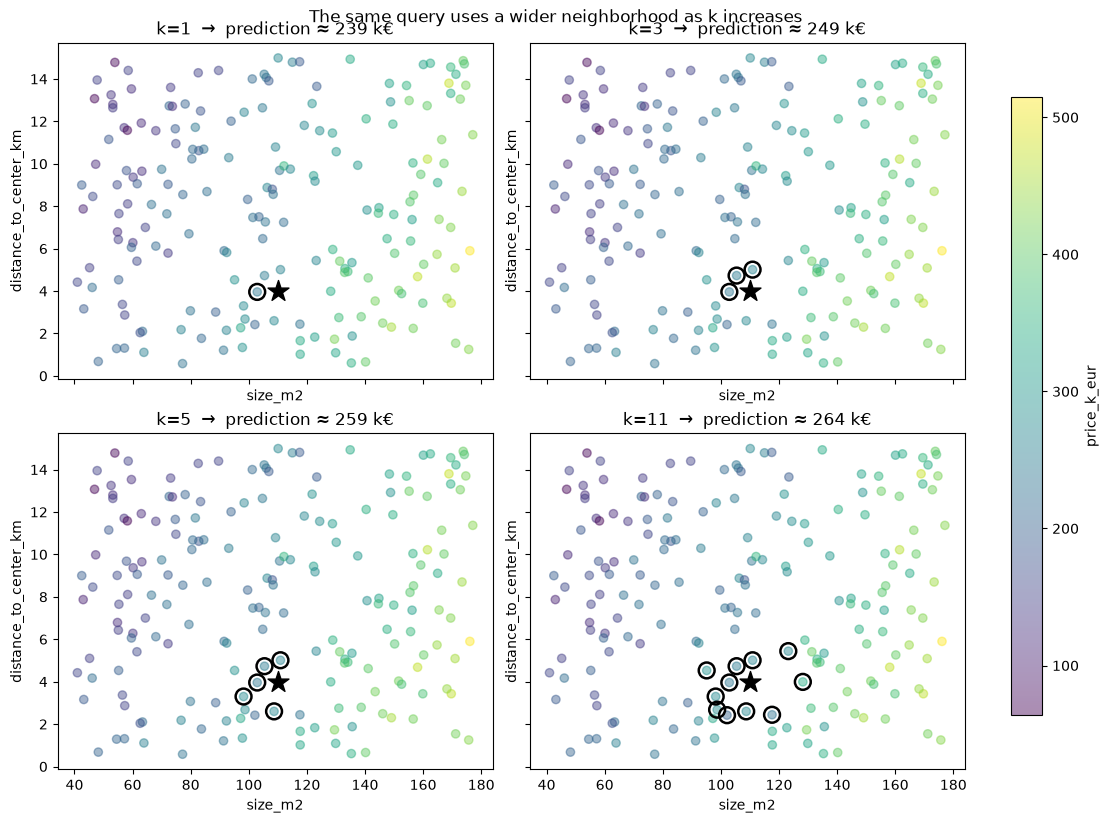

In [3]:
plot_knn_neighborhoods()

## 1.2 The most important KNN hyperparameters

There is no universal best value. Use validation or cross-validation. The ranges below are **starting points**, not rules.

| Hyperparameter | What it changes | Useful first values |
|---|---|---|
| `n_neighbors` | neighborhood size | `1, 3, 5, 7, 11, 15, 21, 31` |
| `weights` | contribution of each neighbor | `"uniform"`, `"distance"` | 
| `p` | Minkowski distance | `1`, `2` | `1` = Manhattan, `2` = Euclidean |
| `metric` | geometry of similarity | usually keep Minkowski first | change only when domain knowledge justifies another notion of distance |
| `leaf_size`, search algorithm | computation | usually leave defaults initially | mostly affects speed/memory, not the statistical model |


## 1.3 Input format: why KNN usually needs scaling

KNN uses distances, so **units become part of the model**.

Suppose one feature ranges approximately from 40 to 180 (size_m2) and another from 0 to 15 (distance_to_center_km). A difference of 40 m² can numerically dominate a difference of 4 km even though the units are unrelated.

StandardScaler transforms each numerical feature as


$z=\frac{x-\mu}{\sigma}$

After scaling, a one-unit difference means approximately one standard deviation on either variable. This does not make the variables inherently equally important; it simply prevents their original units from deciding importance accidentally.

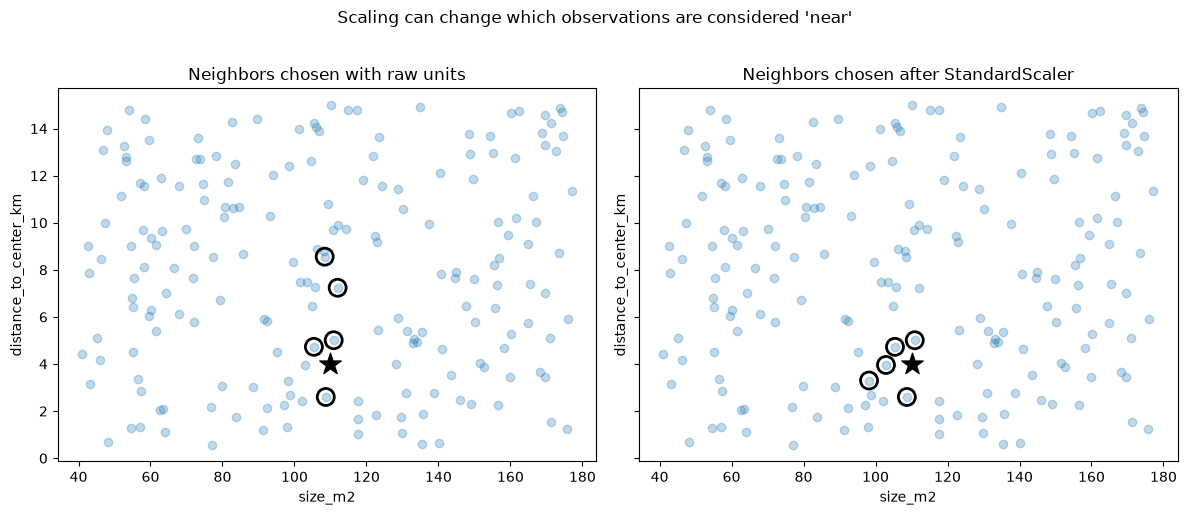

In [4]:
plot_knn_scaling()

### Categorical variables in KNN

KNN implementations such as scikit-learn expect a NUMERICAL matrix, so strings such as "urban" or "suburban" must be encoded. 

#### One-hot encoding: categories without an order

`OneHotEncoder` creates one binary column for each observed category. For example:

```text
urban       → [1, 0, 0]
suburban    → [0, 1, 0]
residential → [0, 0, 1]
```

This is appropriate for a **nominal** variable such as neighborhood, where no category is naturally greater than another. With Euclidean distance, two observations in the same category contribute 0 to the distance through these columns; two different categories contribute the same mismatch distance. No artificial ordering is introduced.

However, one-hot encoding is not neutral:

- a variable with many categories creates many columns (!!!);
- rare or unseen categories need an explicit policy such as `handle_unknown="ignore"`;
- the new binary columns still influence distance, so irrelevant categorical variables can damage the neighborhood.

#### Ordinal encoding: categories with a real order

`OrdinalEncoder` maps ordered categories to ranks. For example:

```text
E → 0, D → 1, C → 2, B → 3, A → 4
```

This can make sense for energy_rating because the categories have a genuine order. In KNN, it also means that an A rating is treated as farther from E than from B.

That interpretation carries a stronger assumption: consecutive levels are treated as equally spaced. If the difference between A and B is not comparable with the difference between D and E, ordinal encoding may distort the distances. Its numerical range may also need scaling or explicit weighting relative to the other features.

In [5]:
categorical_example = houses[["neighborhood", "energy_rating"]].head(6)

categorical_encoder = ColumnTransformer([
    ("neighborhood_onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["neighborhood"]),
    ("energy_ordinal", OrdinalEncoder(categories=[["E", "D", "C", "B", "A"]]), ["energy_rating"]),
], verbose_feature_names_out=False)

encoded_values = categorical_encoder.fit_transform(categorical_example)
encoded_example = pd.DataFrame(
    encoded_values,
    columns=categorical_encoder.get_feature_names_out(),
    index=categorical_example.index,
)

display(categorical_example)
display(encoded_example)


,neighborhood,energy_rating
0,suburban,C
1,residential,A
2,suburban,A
3,suburban,C
4,urban,C
5,residential,A


,neighborhood_residential,neighborhood_suburban,neighborhood_urban,energy_rating
0,0.0,1.0,0.0,2.0
1,1.0,0.0,0.0,4.0
2,0.0,1.0,0.0,4.0
3,0.0,1.0,0.0,2.0
4,0.0,0.0,1.0,2.0
5,1.0,0.0,0.0,4.0


# 2. Decision trees — prediction by recursive rules

A regression tree does something fundamentally different from KNN.

It repeatedly asks questions of the form

```text
size_m2 <= 104.5 ?
age_years <= 18.5 ?
energy_rating <= some encoded threshold ?
```

Each question partitions the training observations. When a leaf is reached, the regression prediction is typically the **mean target value of the observations in that leaf**.

The model is therefore a set of nested **if/else rules**, and its prediction surface is piecewise constant.

## 2.1 How does the tree choose the next split?

For regression with the usual squared-error criterion, consider a node containing target values \(y_1,\ldots,y_n\).

The node impurity is the mean squared error around its mean:

$$
MSE_{parent}=\frac{1}{n}\sum_i (y_i-\bar y)^2.
$$

For every candidate feature and threshold, the tree creates a left and a right child and computes

$$
MSE_{children}=\frac{n_L}{n}MSE_L+\frac{n_R}{n}MSE_R.
$$

The preferred split is the one with the **largest reduction in impurity**:

$$
\text{gain}=MSE_{parent}-MSE_{children}.
$$

So the tree is not choosing a threshold visually or arbitrarily: it is searching for the rule that most reduces prediction error **at that node**. The same procedure is then repeated recursively inside each child.

The next figure shows candidate numerical thresholds. A production tree also evaluates the transformed categorical features produced by preprocessing.

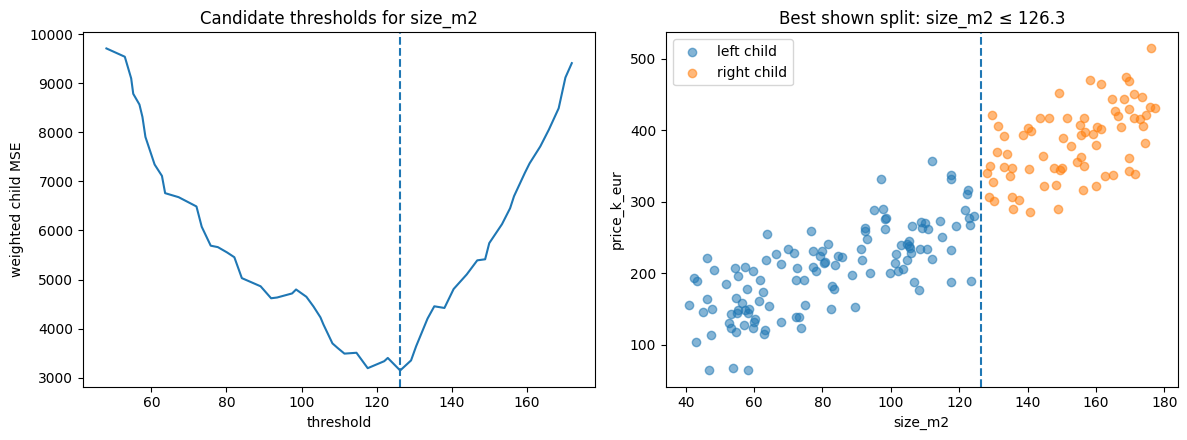

,feature,threshold,weighted_child_MSE,MSE_reduction,n_left,n_right
0,size_m2,126.30,3147.623,7373.095,120,72
1,size_m2,117.65,3194.413,7326.306,110,82
2,size_m2,122.05,3336.839,7183.880,114,78
3,size_m2,129.20,3352.372,7168.347,123,69
4,size_m2,123.00,3402.987,7117.732,117,75
5,size_m2,111.45,3491.038,7029.681,104,88


In [25]:
show_split_search()

## 2.2 Input format: trees do not need scaling, but categories still need representation

The abstract algorithm can absolutely use a rule such as

```text
neighborhood == "urban"
```

or even

```text
neighborhood in {"urban", "suburban"}
```

The reason we encode is implementation-specific: scikit-learn's standard DecisionTreeRegressor expects a numerical feature matrix and does not treat arbitrary strings as native categorical split candidates.

## 2.3 A small tree is readable

The next tree is deliberately restricted to depth 2. Each internal node contains a split rule. Each leaf contains a constant prediction.

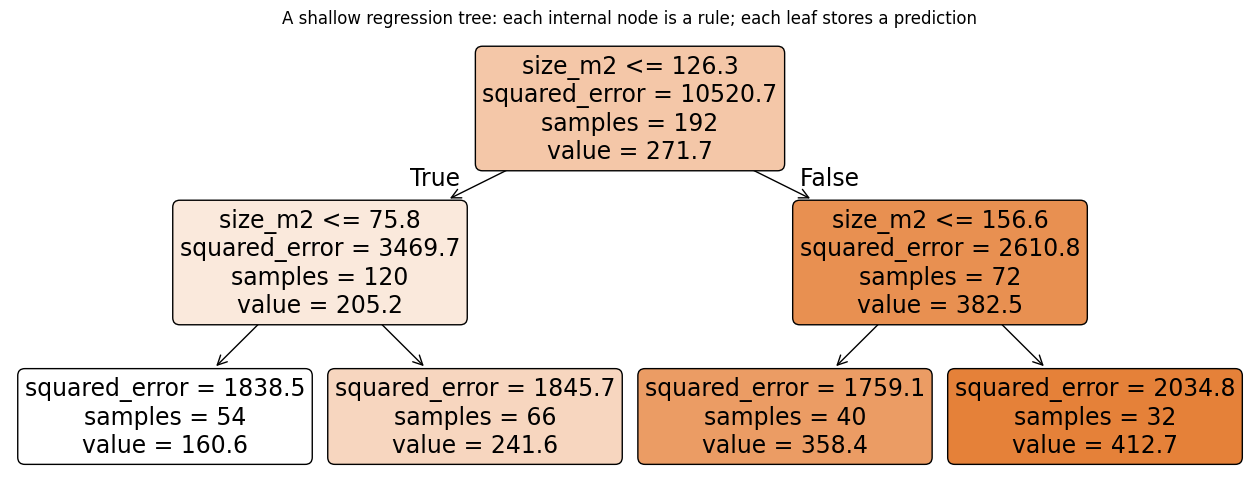

In [26]:
show_shallow_tree()

## 2.4 The most important Decision-tree hyperparameters

| Hyperparameter | What it controls | Useful first values |
|---|---|---|
| `max_depth` | maximum number of recursive levels | `2, 3, 4, 5, 7, 10, None` |
| `min_samples_leaf` | minimum observations in a leaf | `1, 2, 5, 10, 20`, or small fractions for large datasets |
| `min_samples_split` | minimum observations required before a node may split | `2, 5, 10, 20, 40` |

Other parameters exist, but they are better introduced when there is a reason to use them.

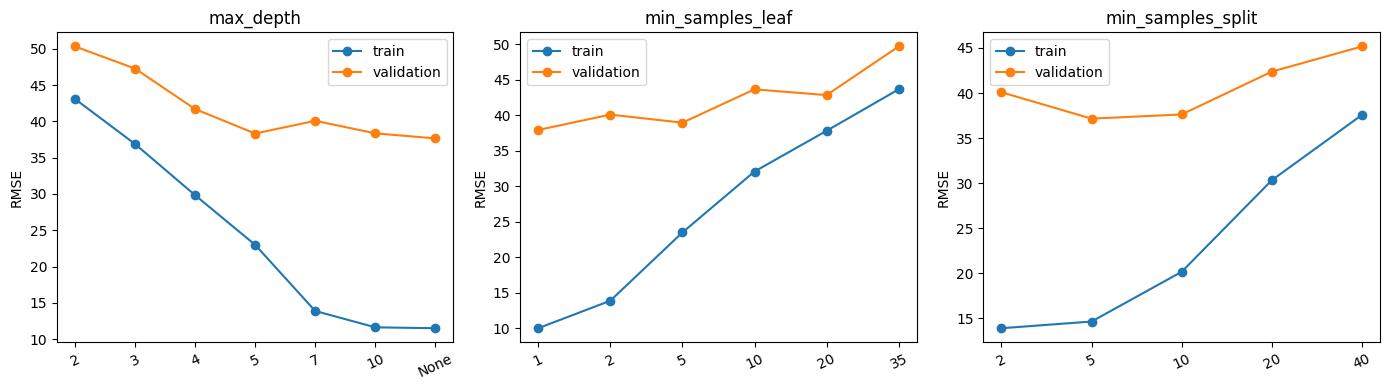

In [27]:
tree_results = tree_sweep()
plot_tree_sweep(tree_results)

# 3. Random forests — many randomized trees, one averaged prediction

A single decision tree can be powerful, but it is also unstable: relatively small changes in the training sample can alter an early split, and that can change many later decisions.

A random forest attacks that instability by training **many decision trees** that are deliberately made different from one another, then averaging their predictions.

Two sources of randomness are central:

1. **row randomness:** each tree is trained on a bootstrap sample of the training observations;
2. **feature randomness:** at each split, only a random subset of features is considered.

## 3.1 What averaging many trees looks like

The thin lines below are predictions from individual trees for the same controlled set of houses. The thick line is their average.

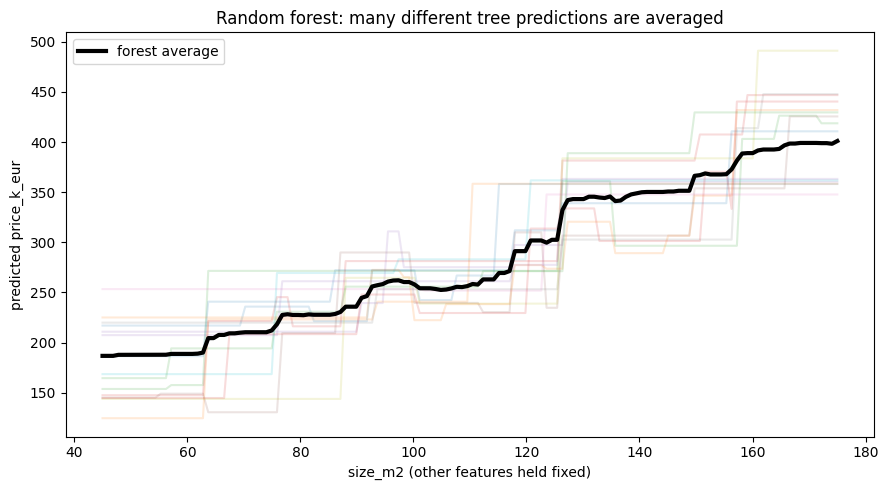

In [28]:
show_forest_predictions()

A second way to see the same idea is to perturb the training sample repeatedly.

A single deep tree can react strongly to those perturbations. A random forest should usually be less sensitive because each final prediction already averages across many different trees.

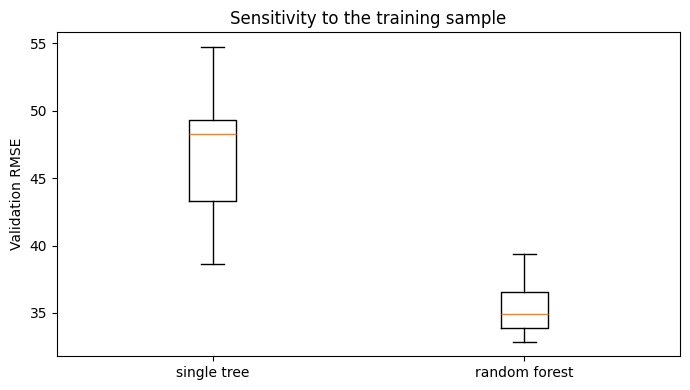

,model,mean_validation_RMSE,std_across_resamples
0,single tree,47.029,4.131
1,random forest,35.312,1.685


In [29]:
display(compare_resampling_stability())

## 3.2 Why random feature subsets matter

Bootstrap sampling makes trees see different rows, but trees can still become similar if the same strong predictors dominate their early splits.

Random forests therefore also randomize the **candidate features at each split**. This is controlled by max_features.

Reducing max_features often lowers the correlation between tree predictions. But there is a trade-off:

```text
fewer candidate features per split
        ↓
more diverse trees
        ↓
but potentially weaker individual trees
```

So **lower correlation is not automatically better**.

## 3.3 Input format for random forests

The practical input rules are almost the same as for decision trees:

- **numerical variables:** can usually be used in their original scale;
- **scaling:** normally unnecessary because splits depend on order and thresholds, not Euclidean distance;
- **nominal categorical variables:** in a standard scikit-learn workflow, encode them, typically with one-hot encoding;
- **ordinal categorical variables:** ordinal encoding can be reasonable when the order is real and meaningful;
- **missing values:** support depends on the estimator and version, so preprocessing choices should be made deliberately rather than assumed;
- **preprocessing:** anything learned from data must be fitted using training data only.

The forest handles nonlinearities and interactions well, but it still cannot rescue an incorrect experimental design, target leakage, or meaningless input representation.

## 3.4 Random-forest hyperparameters to experiment with

These are the parameters worth understanding first.

| Hyperparameter | What it controls | Useful first values |
|---|---|---|
| `n_estimators` | number of trees | `100, 200, 300, 500` |
| `max_features` | candidate features at each split | `1.0, 0.7, 0.5, "sqrt"` | 
| `max_depth` | maximum depth of each tree | `None, 5, 8, 12, 20` |
| `min_samples_leaf` | minimum observations in a leaf | `1, 2, 5, 10, 20` | 
| `max_samples` | bootstrap sample size per tree | `None, 0.6, 0.8` |

There is no universal best grid. A good first search usually focuses on **max_features and min_samples_leaf**, while choosing enough trees for stable results.

n_estimators is usually not a delicate regularization parameter: once enough trees are present, adding more tends mainly to stabilize the average at additional computational cost.

# 4. GridSearchCV — systematic hyperparameter selection

So far, we changed one hyperparameter at a time and inspected validation RMSE. That is useful for understanding each parameter, but hyperparameters can **interact**.

GridSearchCV automates a controlled experiment:

1. define a finite grid of candidate values;
2. create every combination in that grid;
3. evaluate each combination with cross-validation;
4. rank the combinations by their mean validation score;
5. refit the best combination on all development data.

With 24 combinations and 5 folds, the search performs $24 \times 5 = 120$ model fits, followed by one final refit of the winning configuration. Grid search is systematic, but it only searches the values we provide; it cannot discover values outside the grid.

## 5.1 Define and run the search

refit=True means that, after cross-validation, GridSearchCV trains the winning pipeline once more on all development rows.

In [30]:
# Keep the test set untouched and use the remaining rows for model selection.
X_development = pd.concat([X_train, X_val])
y_development = pd.concat([y_train, y_val])

tree_preprocess = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("nominal", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
    ("ordinal", OrdinalEncoder(categories=[["E", "D", "C", "B", "A"]]), ordinal_cols),
], verbose_feature_names_out=False)

pipeline = Pipeline([
    ("preprocess", tree_preprocess),
    ("model", RandomForestRegressor(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 300],
    "model__max_features": [0.5, 0.8],
    "model__min_samples_leaf": [1, 3, 7],
    "model__max_depth": [None, 10],
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)

grid_search.fit(X_development, y_development)

n_combinations = int(
    np.prod([len(values) for values in param_grid.values()])
)

print(
    f"{n_combinations} combinations × 5 folds = "
    f"{n_combinations * 5} cross-validation fits"
)

24 combinations × 5 folds = 120 cross-validation fits


## 5.2 Inspect the evidence, not only `best_params_`

The best row is useful, but nearby configurations matter too. If several settings have very similar mean CV RMSE relative to their fold-to-fold variability, the data do not strongly distinguish them. In that situation, prefer the simpler or cheaper configuration.

The train–CV gap is also informative: a very low training RMSE combined with a much higher CV RMSE is evidence of overfitting.

In [22]:
search_results = (
    pd.DataFrame(grid_search.cv_results_)
    .assign(
        mean_train_RMSE=lambda d: -d["mean_train_score"],
        mean_CV_RMSE=lambda d: -d["mean_test_score"],
        fold_to_fold_std=lambda d: d["std_test_score"],
    )
    .sort_values("rank_test_score")
)

columns_to_show = [
    "rank_test_score",
    "param_model__n_estimators",
    "param_model__max_features",
    "param_model__min_samples_leaf",
    "param_model__max_depth",
    "mean_train_RMSE",
    "mean_CV_RMSE",
    "fold_to_fold_std",
]

top_results = search_results[columns_to_show].head(8).copy()
for column in ["mean_train_RMSE", "mean_CV_RMSE", "fold_to_fold_std"]:
    top_results[column] = top_results[column].round(2)
display(top_results)


,rank_test_score,param_model__n_estimators,param_model__max_features,param_model__min_samples_leaf,param_model__max_depth,mean_train_RMSE,mean_CV_RMSE,fold_to_fold_std
13,1,300,0.5,1,10,11.33,29.73,2.68
12,2,100,0.5,1,10,11.56,29.74,2.24
1,3,300,0.5,1,None,11.33,29.86,2.66
7,4,300,0.8,1,None,11.32,30.12,3.25
0,5,100,0.5,1,None,11.56,30.18,2.59
19,6,300,0.8,1,10,11.36,30.31,3.23
18,7,100,0.8,1,10,11.55,30.36,3.17
6,8,100,0.8,1,None,11.57,30.63,3.02


## 5.3 Final evaluation on the untouched test set

best_estimator_ is already refitted on all development rows. We now use the test set once to estimate performance on new data.

This final score is **not guaranteed to beat every manually chosen model on one particular test sample**. The benefit of GridSearchCV is a reproducible selection procedure that averages evidence across folds. If we inspect the test result and then change the grid repeatedly, the test set quietly becomes another validation set and stops being an honest final check.

In [21]:
best_forest = grid_search.best_estimator_
test_prediction = best_forest.predict(X_test)

print("Best hyperparameters:")
display(pd.Series(grid_search.best_params_, name="value").to_frame())

final_result = pd.DataFrame({
    "estimate": ["Mean 5-fold CV", "Untouched test"],
    "RMSE": [-grid_search.best_score_, root_mean_squared_error(y_test, test_prediction)],
    "MAE": [np.nan, mean_absolute_error(y_test, test_prediction)],
    "R2": [np.nan, r2_score(y_test, test_prediction)],
})
display(final_result.round(3))


Best hyperparameters:


,value
model__max_depth,10.0
model__max_features,0.5
model__min_samples_leaf,1.0
model__n_estimators,300.0


,estimate,RMSE,MAE,R2
0,Mean 5-fold CV,29.732,NaN,NaN
1,Untouched test,28.693,23.744,0.911
